# Step 1 — Exploratory Data Analysis


## Instructor Effectiveness Modeling

## 1. Exploratory Data Analysis (EDA)

### Objective
The objective of this analysis is to understand instructor performance using learner outcomes, student engagement, and learner feedback metrics.

We will examine data structure, distributions, missing values, duplicate records, outliers, and relationships between variables before performing feature engineering and machine learning.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [4]:
df=pd.read_csv("dataset_accredian.csv")

In [5]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

# First five rows
display(df.head())

# Random five rows
display(df.sample(5))

# Column names
print(df.columns.tolist())



Dataset Shape: (2000, 12)


,batch_id,instructor_id,course_id,completion_rate,avg_score_improved,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_submission,feedback_response_rate
0,B_1861,I_044,C_01,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
1,B_0354,I_119,C_06,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
2,B_1334,I_050,C_03,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
3,B_0906,I_024,C_21,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
4,B_1290,I_001,C_08,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


,batch_id,instructor_id,course_id,completion_rate,avg_score_improved,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_submission,feedback_response_rate
1805,B_1758,I_038,C_07,0.403991,19.757667,86.072848,0.653292,0.594298,0.535528,0.266970,4.332617,0.661304
77,B_0788,I_035,C_05,0.551214,18.409306,62.709406,0.480989,0.847493,0.889744,0.346113,4.139422,0.739927
1595,B_1020,I_012,C_02,0.539303,27.266778,76.424950,0.457690,0.829498,1.000000,0.348275,4.475757,0.714593
1365,B_0037,I_049,C_21,0.755075,24.694158,83.227112,0.231976,0.907234,1.000000,0.271141,4.080353,0.981754
1555,B_0686,I_115,C_16,0.634403,20.800339,77.656735,0.351606,0.566605,0.800823,0.164088,4.522271,0.496540


['batch_id', 'instructor_id', 'course_id', 'completion_rate', 'avg_score_improved', 'avg_quiz_score', 'dropout_rate', 'avg_watch_time', 'assignment_submission_rate', 'forum_activity_rate', 'avg_feedback_submission', 'feedback_response_rate']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   object 
 1   instructor_id               2000 non-null   object 
 2   course_id                   2000 non-null   object 
 3   completion_rate             2000 non-null   float64
 4   avg_score_improved          2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_submission     2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), object(3)
memory usage: 187.6+ KB


In [7]:
# Missing values in each column
print(df.isnull().sum())

# Total missing values
print("Total Missing Values:", df.isnull().sum().sum())

# Percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

batch_id                      0
instructor_id                 0
course_id                     0
completion_rate               0
avg_score_improved            0
avg_quiz_score                0
dropout_rate                  0
avg_watch_time                0
assignment_submission_rate    0
forum_activity_rate           0
avg_feedback_submission       0
feedback_response_rate        0
dtype: int64
Total Missing Values: 0
batch_id                      0.0
instructor_id                 0.0
course_id                     0.0
completion_rate               0.0
avg_score_improved            0.0
avg_quiz_score                0.0
dropout_rate                  0.0
avg_watch_time                0.0
assignment_submission_rate    0.0
forum_activity_rate           0.0
avg_feedback_submission       0.0
feedback_response_rate        0.0
dtype: float64


In [8]:
print("Total Duplicate Rows:", df.duplicated().sum())

print("Duplicate Batch IDs:", df['batch_id'].duplicated().sum())

Total Duplicate Rows: 0
Duplicate Batch IDs: 0


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
completion_rate,2000.0,0.602808,0.159667,0.300000,0.489260,0.603091,0.712797,0.980000
avg_score_improved,2000.0,27.035844,5.716641,6.159240,23.124673,26.938629,30.885600,40.000000
avg_quiz_score,2000.0,77.956126,10.695618,40.386725,70.897590,78.020567,85.444286,100.000000
dropout_rate,2000.0,0.394883,0.162747,0.020000,0.280035,0.394820,0.511432,0.700000
avg_watch_time,2000.0,0.776515,0.145231,0.287440,0.675076,0.780330,0.894242,1.000000
assignment_submission_rate,2000.0,0.753188,0.148058,0.251111,0.652110,0.756380,0.856458,1.000000
forum_activity_rate,2000.0,0.250300,0.100640,0.000000,0.179845,0.249771,0.319204,0.641111
avg_feedback_submission,2000.0,4.207134,0.419209,2.639915,3.918986,4.205989,4.503437,5.000000
feedback_response_rate,2000.0,0.736519,0.149412,0.259935,0.633293,0.737213,0.845876,1.000000


In [10]:
# check value range
percentage_columns = [
    'completion_rate',
    'dropout_rate',
    'avg_watch_time',
    'assignment_submission_rate',
    'forum_activity_rate',
    'feedback_response_rate'
]

for col in percentage_columns:
    print(f"\n{col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())


completion_rate
Minimum: 0.3
Maximum: 0.98

dropout_rate
Minimum: 0.02
Maximum: 0.7

avg_watch_time
Minimum: 0.287439904
Maximum: 1.0

assignment_submission_rate
Minimum: 0.251110804
Maximum: 1.0

forum_activity_rate
Minimum: 0.0
Maximum: 0.641111144

feedback_response_rate
Minimum: 0.259935242
Maximum: 1.0


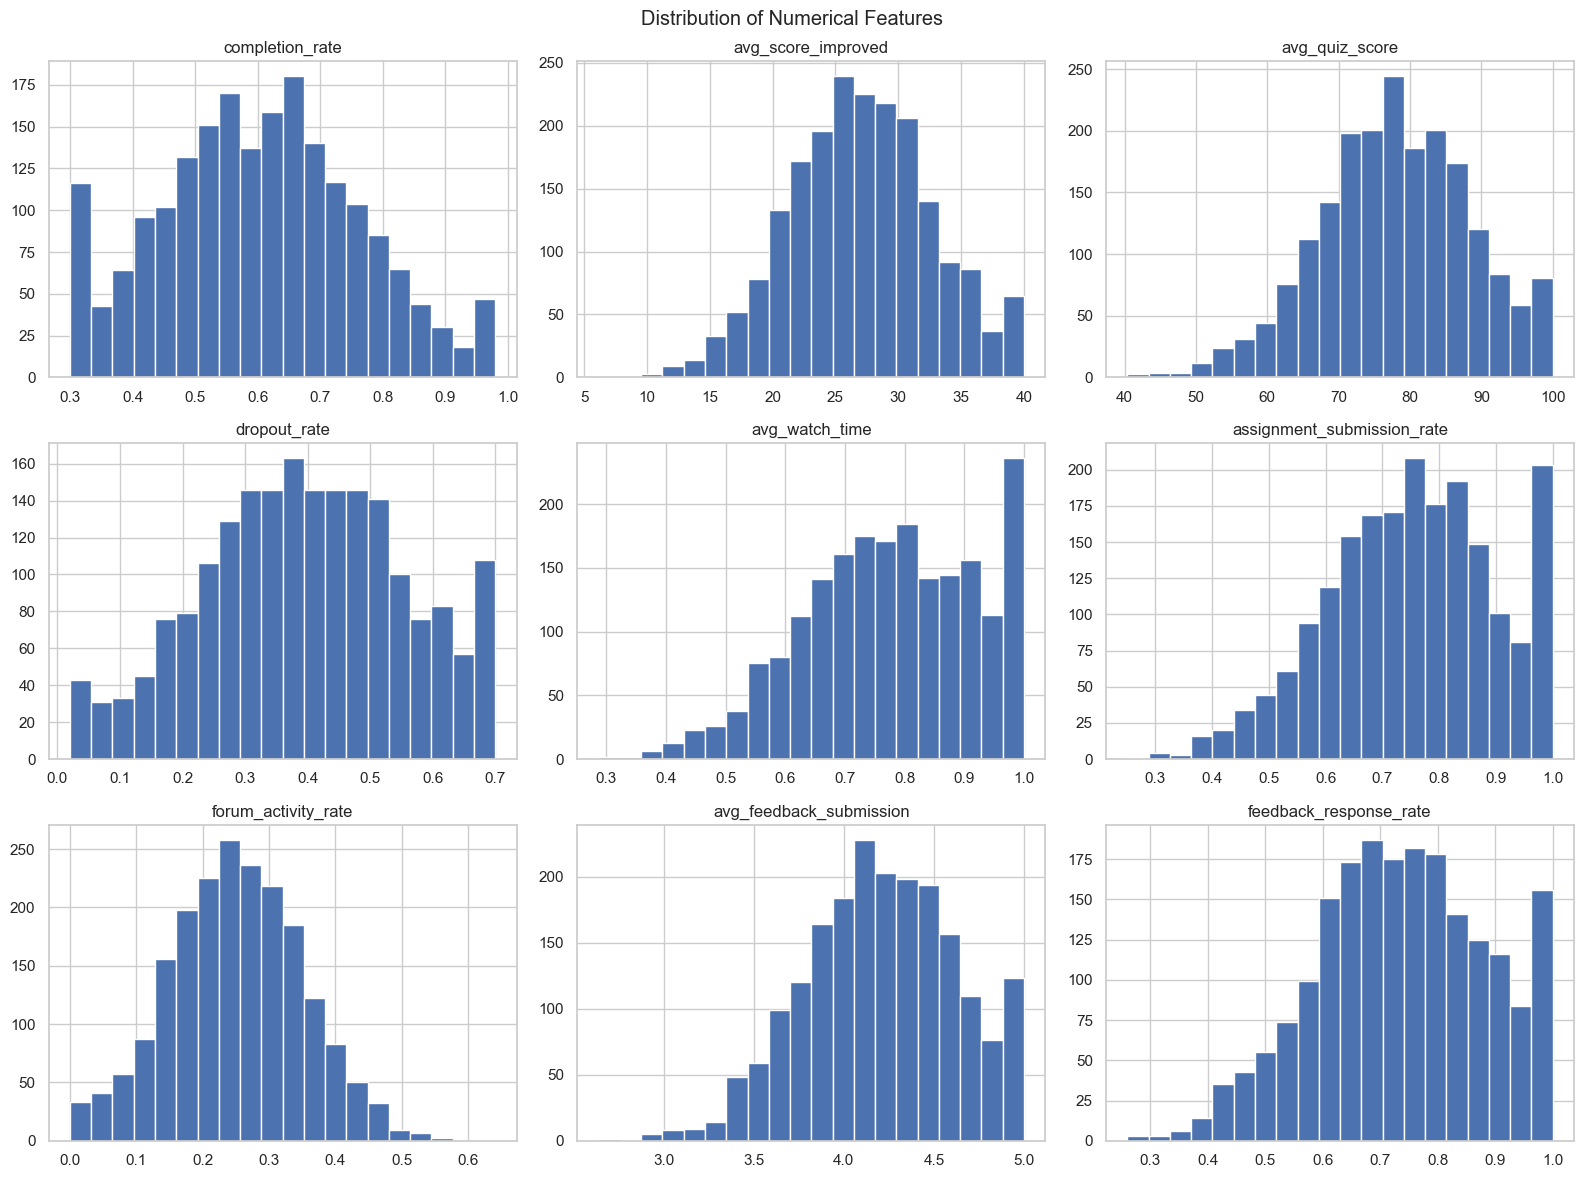

In [11]:
df.hist(figsize=(16, 12), bins=20)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

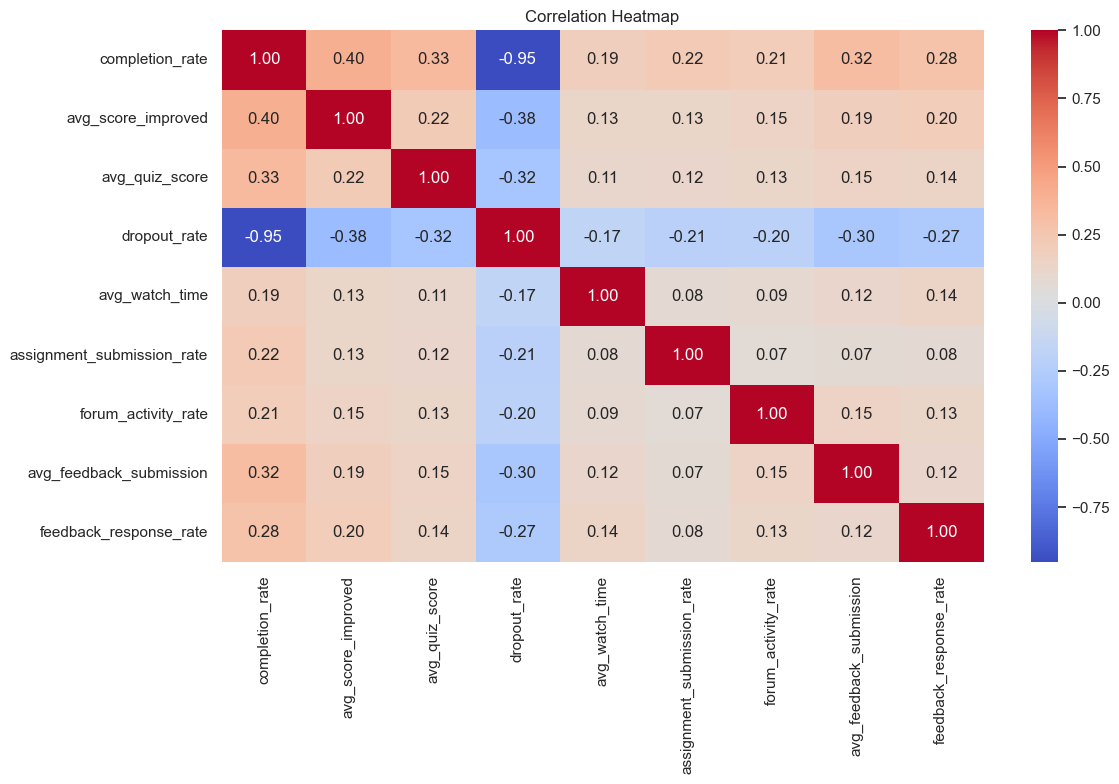

In [12]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

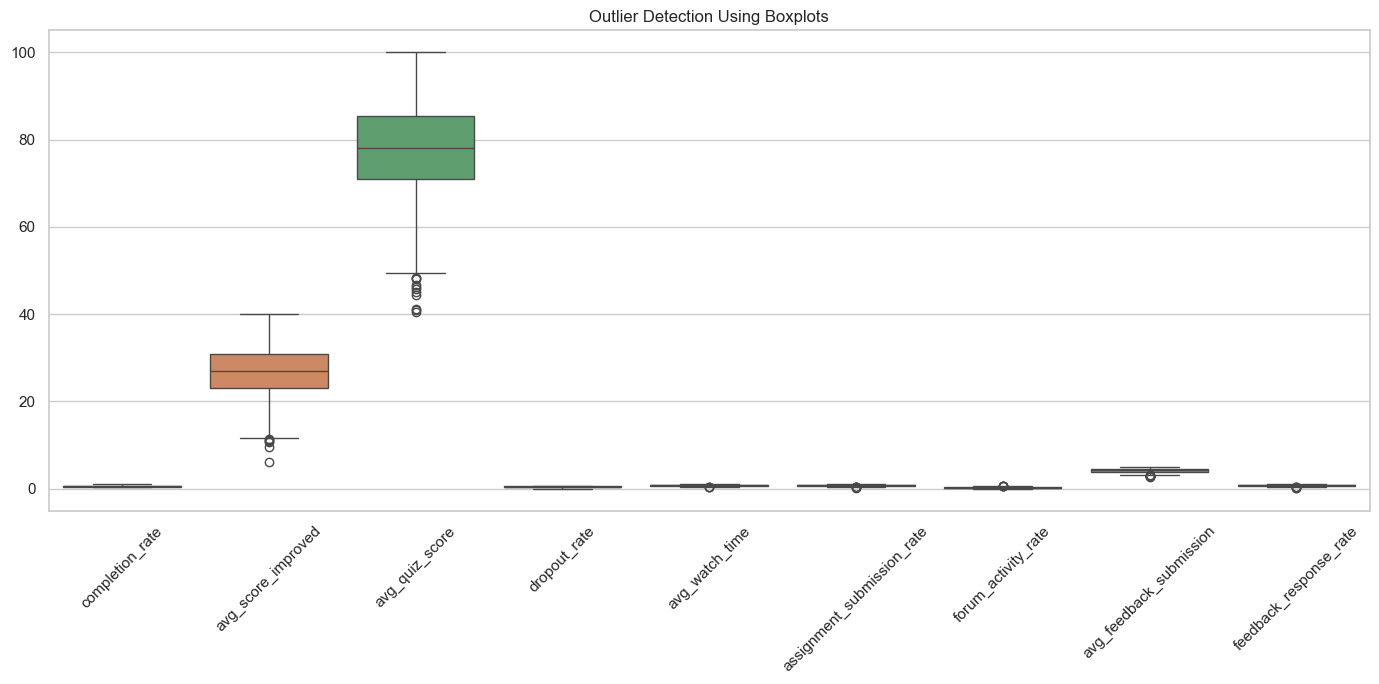

In [13]:
plt.figure(figsize=(14, 7))

sns.boxplot(data=df.select_dtypes(include=np.number))

plt.xticks(rotation=45)
plt.title("Outlier Detection Using Boxplots")
plt.tight_layout()
plt.show()

In [15]:
df['completion_dropout_sum'] = (
    df['completion_rate'] + df['dropout_rate']
)

print(df['completion_dropout_sum'].describe())

count    2000.000000
mean        0.997692
std         0.049259
min         0.828710
25%         0.965302
50%         0.999425
75%         1.029358
max         1.160438
Name: completion_dropout_sum, dtype: float64



# Exploratory Data Analysis - Key Findings

### 1. Dataset Overview
The dataset contains 2,000 batch-level records and 12 columns.

### 2. Data Quality
- No missing values were identified.
- No duplicate rows were found.
- All batch IDs are unique.
- Numerical and categorical features were identified.

### 3. Descriptive Statistics
- Average completion rate is approximately 60.3%.
- Average dropout rate is approximately 39.5%.
- Average quiz score is approximately 77.96.
- Average watch time is approximately 77.7%.
- Average assignment submission rate is approximately 75.3%.
- Average feedback score is approximately 4.21 out of 5.

### 4. Distribution Analysis
- Completion rates are mostly concentrated between 0.50 and 0.70.
- Score improvement is concentrated around 23–32 points.
- Quiz scores are mostly concentrated between 70 and 90.
- Engagement metrics generally show higher values for watch time and assignment submission.

### 5. Correlation Analysis
- Completion rate and dropout rate have a strong negative correlation (-0.95).
- Completion rate has a moderate positive correlation with score improvement (0.40).
- Completion rate has a positive correlation with quiz score (0.33).
- Dropout rate has a negative correlation with score improvement (-0.38).

### 6. Outlier Analysis
Boxplots identified potential outliers in some numerical features, particularly score improvement and quiz score. These observations will be investigated rather than automatically removed.

### 7. Initial Insights
Learner outcomes, engagement and feedback provide different perspectives on instructor performance. Completion and dropout rates show substantial overlap, which should be considered during feature engineering.

Overall, the dataset appears complete and suitable for further analysis, subject to validation of unusual values and feature definitions.


### 8. Additional Investigation: Completion and Dropout Relationship

The correlation between completion_rate and dropout_rate is -0.95, indicating a very strong negative relationship.

Their combined value has a mean of approximately 0.998, with a standard deviation of 0.049.

However, the sum is not consistently equal to 1. Therefore, the two variables are not exact complements.

Both features will be retained for further analysis, while considering their overlapping information during effectiveness score construction.


# Step 2: Instructor Effectiveness Score


## 2. Defining Instructor Effectiveness Score

Instructor effectiveness is defined as the ability to achieve positive learner outcomes, maintain student engagement, and provide a satisfactory learning experience.

Since the available metrics have different numerical scales, Min-Max normalization is applied to score improvement and quiz score. Feedback ratings are scaled from 1–5 to 0–1.

The final score combines three dimensions:

- Learner Outcomes: 50%
- Student Engagement: 30%
- Student Feedback: 20%

Completion and dropout are combined into a retention score to reduce overlapping information.

The resulting Instructor Effectiveness Score ranges from 0 to 100.


In [17]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df[['score_improvement_norm', 'quiz_score_norm']] = scaler.fit_transform(
    df[['avg_score_improved', 'avg_quiz_score']]
)

# Normalize feedback score from 1–5 to 0–1
df['feedback_score_norm'] = (
    (df['avg_feedback_submission'] - 1) / 4
)

In [18]:
# 1. Retention score
df['retention_score'] = (
    df['completion_rate'] + (1 - df['dropout_rate'])
) / 2

# 2. Learner outcome score
df['learner_outcome_score'] = (
    df['retention_score'] +
    df['score_improvement_norm'] +
    df['quiz_score_norm']
) / 3

# 3. Engagement score
df['engagement_score'] = (
    df['avg_watch_time'] +
    df['assignment_submission_rate'] +
    df['forum_activity_rate']
) / 3

# 4. Feedback score
df['feedback_score'] = (
    df['feedback_score_norm'] +
    df['feedback_response_rate']
) / 2

In [19]:
df['effectiveness_score'] = (
    0.50 * df['learner_outcome_score'] +
    0.30 * df['engagement_score'] +
    0.20 * df['feedback_score']
) * 100

In [20]:
print(df['effectiveness_score'].describe())

count    2000.000000
mean       64.034536
std         8.352111
min        31.766350
25%        58.484177
50%        64.136313
75%        69.637172
max        90.008575
Name: effectiveness_score, dtype: float64


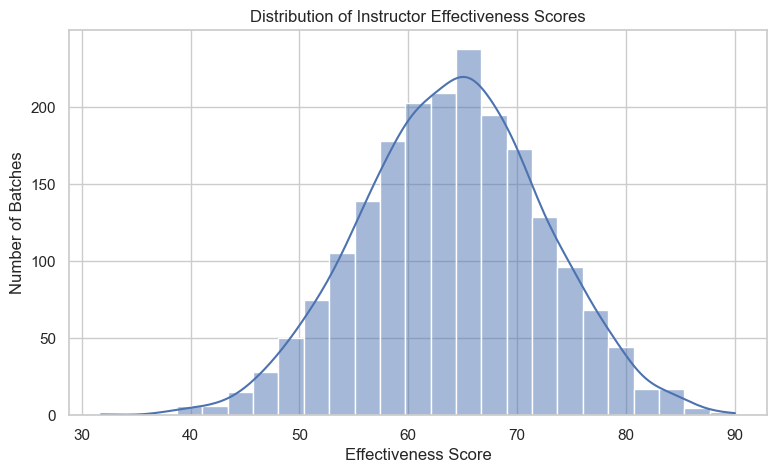

In [21]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df['effectiveness_score'],
    bins=25,
    kde=True
)

plt.title("Distribution of Instructor Effectiveness Scores")
plt.xlabel("Effectiveness Score")
plt.ylabel("Number of Batches")

plt.show()


## Effectiveness Score Distribution

The calculated Instructor Effectiveness Score has the following characteristics:

- Mean score: 64.03
- Median score: 64.14
- Standard deviation: 8.35
- Minimum score: 31.77
- Maximum score: 90.01

### Key Observations

1. The average batch effectiveness score is approximately 64.
2. Most scores are concentrated between approximately 58 and 70.
3. The distribution is approximately bell-shaped.
4. There is noticeable variation between batch performance scores.
5. Some batches have substantially lower or higher scores than the average.

### Next Step

The effectiveness score is currently calculated at batch level. We will aggregate these scores using instructor_id to obtain one effectiveness score per instructor.

The aggregated instructor scores will then be converted into Low, Medium and High effectiveness tiers.


# Step 3: Instructor-level aggregation

In [22]:
# Aggregate batch-level data to instructor-level data

instructor_df = df.groupby('instructor_id').agg(
    effectiveness_score=('effectiveness_score', 'mean'),
    learner_outcome_score=('learner_outcome_score', 'mean'),
    engagement_score=('engagement_score', 'mean'),
    feedback_score=('feedback_score', 'mean'),
    total_batches=('batch_id', 'count')
).reset_index()

# Check the new dataset
print("Instructor Dataset Shape:", instructor_df.shape)

display(instructor_df.head())

Instructor Dataset Shape: (120, 6)


,instructor_id,effectiveness_score,learner_outcome_score,engagement_score,feedback_score,total_batches
0,I_001,62.131761,0.595985,0.577986,0.749647,25
1,I_002,70.963121,0.714965,0.633799,0.810044,20
2,I_003,71.719852,0.720615,0.631424,0.837320,18
3,I_004,58.952230,0.525391,0.592569,0.745281,17
4,I_005,76.427629,0.800090,0.685829,0.792413,19


In [23]:
print(instructor_df['effectiveness_score'].describe())

print("Unique instructors:",
      instructor_df['instructor_id'].nunique())

count    120.000000
mean      63.976015
std        6.945249
min       45.950193
25%       59.783671
50%       63.938008
75%       67.972624
max       82.407029
Name: effectiveness_score, dtype: float64
Unique instructors: 120


# Step 4: Implement tier assignment

In [24]:
instructor_df['effectiveness_tier'] = pd.qcut(
    instructor_df['effectiveness_score'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

In [25]:
print(instructor_df['effectiveness_tier'].value_counts())

effectiveness_tier
Low       40
Medium    40
High      40
Name: count, dtype: int64


effectiveness_tier
Low       33.333333
Medium    33.333333
High      33.333333
Name: proportion, dtype: float64


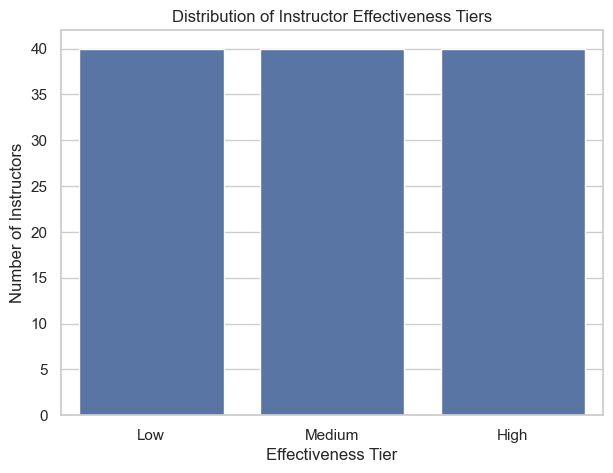

In [27]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=instructor_df,
    x='effectiveness_tier',
    order=['Low', 'Medium', 'High']
)

plt.title('Distribution of Instructor Effectiveness Tiers')
plt.xlabel('Effectiveness Tier')
plt.ylabel('Number of Instructors')

plt.show()

# Step 5: Build a Machine Learning Classification Model

In [28]:
print(instructor_df['effectiveness_tier'].value_counts())

print("\nPercentage distribution:")
print(
    instructor_df['effectiveness_tier']
    .value_counts(normalize=True) * 100
)

effectiveness_tier
Low       40
Medium    40
High      40
Name: count, dtype: int64

Percentage distribution:
effectiveness_tier
Low       33.333333
Medium    33.333333
High      33.333333
Name: proportion, dtype: float64


In [29]:
performance_columns = [
    'completion_rate',
    'avg_score_improved',
    'avg_quiz_score',
    'dropout_rate',
    'avg_watch_time',
    'assignment_submission_rate',
    'forum_activity_rate',
    'avg_feedback_submission',
    'feedback_response_rate'
]

# Aggregate original metrics by instructor
instructor_features = df.groupby('instructor_id').agg(
    **{
        f'{col}_mean': (col, 'mean')
        for col in performance_columns
    },
    total_batches=('batch_id', 'count'),
    unique_courses=('course_id', 'nunique')
).reset_index()

# Attach the target labels
ml_df = instructor_features.merge(
    instructor_df[['instructor_id', 'effectiveness_tier']],
    on='instructor_id',
    how='inner'
)

print("ML Dataset Shape:", ml_df.shape)
display(ml_df.head())

ML Dataset Shape: (120, 13)


,instructor_id,completion_rate_mean,avg_score_improved_mean,avg_quiz_score_mean,dropout_rate_mean,avg_watch_time_mean,assignment_submission_rate_mean,forum_activity_rate_mean,avg_feedback_submission_mean,feedback_response_rate_mean,total_batches,unique_courses,effectiveness_tier
0,I_001,0.543887,26.641462,78.900194,0.470593,0.766513,0.726893,0.240551,4.217743,0.694858,25,16,Medium
1,I_002,0.730874,30.166242,81.737198,0.247194,0.837393,0.774394,0.289610,4.343002,0.784338,20,10,High
2,I_003,0.768447,29.977813,81.590928,0.234828,0.818441,0.779606,0.296224,4.450034,0.812132,18,14,High
3,I_004,0.458328,22.912021,77.680317,0.547261,0.793130,0.758317,0.226259,4.076410,0.721460,17,10,Low
4,I_005,0.859747,32.588652,85.828159,0.145733,0.847026,0.876942,0.333519,4.202516,0.784197,19,13,High


In [30]:
print(instructor_features['total_batches'].describe())

print(
    "Minimum batches:",
    instructor_features['total_batches'].min()
)

print(
    "Maximum batches:",
    instructor_features['total_batches'].max()
)

count    120.000000
mean      16.666667
std        4.582270
min        7.000000
25%       13.750000
50%       17.000000
75%       19.000000
max       31.000000
Name: total_batches, dtype: float64
Minimum batches: 7
Maximum batches: 31


In [31]:
# separate input variable and output
X = ml_df.drop(
    columns=[
        'instructor_id',
        'effectiveness_tier'
    ]
)

y = ml_df['effectiveness_tier']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (120, 11)
Target: (120,)


In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 96
Testing samples: 24


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [34]:
model.fit(X_train, y_train.astype(str))

print("Model training completed!")

Model training completed!


In [35]:
y_pred = model.predict(X_test)

print("Actual:", y_test.astype(str).values)
print("Predicted:", y_pred)

Actual: ['Medium' 'Low' 'Medium' 'Low' 'High' 'Medium' 'High' 'Medium' 'High'
 'Low' 'Low' 'Low' 'High' 'Medium' 'Low' 'Medium' 'High' 'High' 'Medium'
 'Medium' 'Low' 'High' 'High' 'Low']
Predicted: ['Medium' 'Low' 'Medium' 'Low' 'High' 'Medium' 'Medium' 'Medium' 'High'
 'Low' 'Low' 'Low' 'High' 'Medium' 'Low' 'Medium' 'High' 'High' 'Medium'
 'Medium' 'Low' 'High' 'High' 'Low']


#### Classification report

In [36]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test.astype(str),
    y_pred,
    zero_division=0
))

              precision    recall  f1-score   support

        High       1.00      0.88      0.93         8
         Low       1.00      1.00      1.00         8
      Medium       0.89      1.00      0.94         8

    accuracy                           0.96        24
   macro avg       0.96      0.96      0.96        24
weighted avg       0.96      0.96      0.96        24



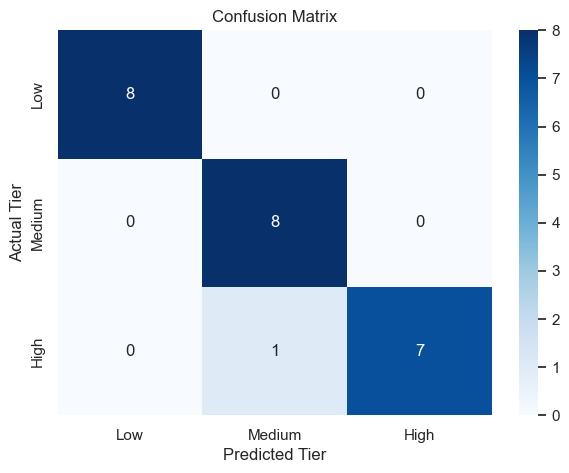

In [37]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test.astype(str),
    y_pred,
    labels=['Low', 'Medium', 'High']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel("Predicted Tier")
plt.ylabel("Actual Tier")
plt.title("Confusion Matrix")

plt.show()

In [38]:
from sklearn.metrics import accuracy_score, f1_score

print("Accuracy:", accuracy_score(
    y_test.astype(str), y_pred
))

print("Macro F1:", f1_score(
    y_test.astype(str),
    y_pred,
    average='macro'
))

Accuracy: 0.9583333333333334
Macro F1: 0.9581699346405229


# Step 6: Feature importance

In [39]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    model,
    X_test,
    y_test.astype(str),
    n_repeats=30,
    random_state=42,
    scoring='f1_macro'
)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': result.importances_mean
}).sort_values(
    by='Importance',
    ascending=False
)

display(importance_df)

,Feature,Importance
1,avg_score_improved_mean,0.131390
2,avg_quiz_score_mean,0.123390
8,feedback_response_rate_mean,0.099607
4,avg_watch_time_mean,0.070615
3,dropout_rate_mean,0.064248
0,completion_rate_mean,0.061366
6,forum_activity_rate_mean,0.006961
7,avg_feedback_submission_mean,0.002643
5,assignment_submission_rate_mean,0.000000
9,total_batches,0.000000



## Feature Importance Analysis

Permutation importance was used to identify the features that contribute most to the Logistic Regression model's predictive performance.

### Key Findings

1. Average score improvement was the most important feature, with an importance of 0.1314.
2. Average quiz score was the second most important feature, with an importance of 0.1234.
3. Feedback response rate also contributed significantly, with an importance of 0.0996.
4. Average watch time, dropout rate and completion rate provided additional predictive information.
5. Forum activity and feedback rating had relatively low importance.
6. Assignment submission rate, total batches and unique courses showed zero measured importance.

### Interpretation

Learning outcomes appear particularly useful for distinguishing instructor effectiveness tiers. Student engagement and feedback participation also contribute to the predictions.

However, permutation importance measures predictive usefulness rather than causal influence. The results should be interpreted cautiously because the test set contains only 24 instructors and some features may be correlated.


# Step 8: Model Comparison

In [40]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42,
    class_weight='balanced'
)

# Train
rf_model.fit(X_train, y_train.astype(str))

# Predict
rf_pred = rf_model.predict(X_test)

print("Random Forest training completed!")

Random Forest training completed!


In [41]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

print("Random Forest Accuracy:",
      accuracy_score(y_test.astype(str), rf_pred))

print("Random Forest Macro F1:",
      f1_score(y_test.astype(str), rf_pred, average='macro'))

print("\nClassification Report:\n")

print(classification_report(
    y_test.astype(str),
    rf_pred,
    labels=['Low', 'Medium', 'High']
))

Random Forest Accuracy: 0.9166666666666666
Random Forest Macro F1: 0.9153439153439153

Classification Report:

              precision    recall  f1-score   support

         Low       1.00      1.00      1.00         8
      Medium       0.80      1.00      0.89         8
        High       1.00      0.75      0.86         8

    accuracy                           0.92        24
   macro avg       0.93      0.92      0.92        24
weighted avg       0.93      0.92      0.92        24



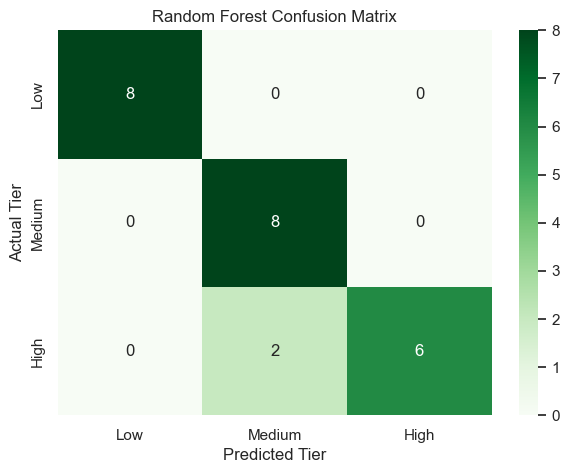

In [42]:
from sklearn.metrics import confusion_matrix

rf_cm = confusion_matrix(
    y_test.astype(str),
    rf_pred,
    labels=['Low', 'Medium', 'High']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel("Predicted Tier")
plt.ylabel("Actual Tier")
plt.title("Random Forest Confusion Matrix")

plt.show()


## Model Comparison

Two classical machine learning algorithms were evaluated:

1. Logistic Regression
2. Random Forest Classifier

### Results

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Accuracy | 95.83% | 91.67% |
| Macro F1 | 0.9582 | 0.9153 |

### Observations

Logistic Regression performed better than Random Forest on the test dataset.

Logistic Regression correctly classified 23 out of 24 instructors, while Random Forest correctly classified 22 out of 24 instructors.

Although Random Forest can capture nonlinear relationships, it did not outperform Logistic Regression in this experiment.

Therefore, Logistic Regression is the current preferred model because of its better test performance and simpler interpretation.

Final model selection will also consider cross-validation results.


### cross validation

In [43]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'macro_f1': 'f1_macro'
}

# Evaluate Logistic Regression
lr_cv = cross_validate(
    model,
    X_train,
    y_train.astype(str),
    cv=cv,
    scoring=scoring
)

# Evaluate Random Forest
rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train.astype(str),
    cv=cv,
    scoring=scoring
)

cv_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'CV Accuracy Mean': [
        lr_cv['test_accuracy'].mean(),
        rf_cv['test_accuracy'].mean()
    ],
    'CV Accuracy Std': [
        lr_cv['test_accuracy'].std(),
        rf_cv['test_accuracy'].std()
    ],
    'CV Macro F1 Mean': [
        lr_cv['test_macro_f1'].mean(),
        rf_cv['test_macro_f1'].mean()
    ],
    'CV Macro F1 Std': [
        lr_cv['test_macro_f1'].std(),
        rf_cv['test_macro_f1'].std()
    ]
})

display(cv_results)

,Model,CV Accuracy Mean,CV Accuracy Std,CV Macro F1 Mean,CV Macro F1 Std
0,Logistic Regression,0.884737,0.052219,0.880411,0.057389
1,Random Forest,0.906316,0.039160,0.905284,0.038111



## Cross-Validation and Final Model Comparison

Stratified 5-fold cross-validation was performed to compare Logistic Regression and Random Forest.

### Cross-Validation Results

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Mean Accuracy | 0.8847 | 0.9063 |
| Accuracy Std | 0.0522 | 0.0392 |
| Mean Macro F1 | 0.8804 | 0.9053 |
| Macro F1 Std | 0.0574 | 0.0381 |

### Findings

1. Random Forest achieved higher mean cross-validation accuracy.
2. Random Forest achieved a higher mean Macro F1-score.
3. Random Forest showed lower variation across validation folds.
4. Logistic Regression achieved higher accuracy on the single held-out test set (95.83% versus 91.67%).

### Model Selection

Random Forest was selected as the primary candidate based on its better average cross-validation performance and lower variability.

Logistic Regression was retained as a simpler baseline model.

The results should be interpreted cautiously because the dataset contains only 120 instructors and the target labels are derived from a constructed scoring methodology.


# Mandatory Analysis Questions – Instructor Effectiveness Modeling

## 1. Which features most influenced instructor effectiveness, and why?

Based on permutation feature importance from the Logistic Regression model, the most influential features were:

- **Average score improvement:** It had the highest importance, indicating that improvement in learners' assessment scores was strongly associated with the predicted effectiveness tier.
- **Average quiz score:** It was the second most important feature, reflecting learners' understanding and academic performance.
- **Feedback response rate:** It was another important feature, providing an indication of learner participation in feedback.
- **Average watch time:** It contributed to the prediction by reflecting how much of the course content learners watched.
- **Completion rate and dropout rate:** These features helped indicate learner retention and course completion.

Other features, such as forum activity, feedback rating, and assignment submission rate, showed relatively low importance in this model.

Overall, learner outcomes and retention-related metrics contributed more to the model's predictions than some engagement and feedback metrics. However, feature importance indicates predictive usefulness, not a direct causal relationship with instructor effectiveness.

## 2. Which variables could be misleading or confounded?

Some variables may not always represent instructor effectiveness accurately because they can be influenced by factors other than teaching quality.

- **Average watch time:** High watch time does not necessarily mean effective teaching. Learners may replay videos because the content is difficult to understand, or videos may continue playing in the background.
- **Average quiz score:** Quiz performance may depend on course difficulty, question difficulty, and learners' prior knowledge, not only on instructor quality.
- **Completion rate:** Completion may be affected by learners' personal schedules, motivation, internet access, or other external circumstances.
- **Dropout rate:** A high dropout rate may result from financial issues, time constraints, or personal problems rather than ineffective teaching.
- **Feedback rating:** Ratings can be subjective and may be influenced by learners' expectations, course difficulty, or personal preferences.
- **Assignment submission rate:** Submission rates may depend on assignment difficulty, deadlines, and learners' availability.

Additionally, completion rate and dropout rate were strongly negatively correlated in the dataset (approximately -0.95). Therefore, they may contain overlapping information.

These variables should be interpreted together rather than treating any single metric as a complete measure of instructor effectiveness.

## 3. How could this model fail in real-world usage?

The model could face several limitations when applied to a real EdTech platform:

1. **Limited dataset:** The analysis uses 2,000 batch records from 120 instructors. This may not represent the diversity of instructors, courses, and learners in a larger platform.

2. **Dependence on constructed labels:** The effectiveness tiers were created using a manually defined Instructor Effectiveness Score. Therefore, the model learns to predict these predefined tiers rather than independently measuring actual teaching quality.

3. **Course difficulty differences:** Instructors teaching advanced courses may receive lower learner scores than instructors teaching beginner-level courses, even if both teach effectively.

4. **Changing learner behaviour:** Learner engagement and completion patterns may change over time, which can reduce model performance on new data.

5. **Small number of instructors:** A limited number of instructor-level records may prevent the model from learning patterns that generalize well to a larger population.

6. **Potential bias:** Differences in learner backgrounds, course types, and available resources could influence the predictions and produce unfair comparisons.

Therefore, the model should be tested on new and diverse data before being considered for real-world applications.

## 4. What additional data would you want to improve this analysis?

To improve the analysis and obtain a more complete understanding of instructor effectiveness, I would collect the following additional data:

- **Course difficulty level:** To understand whether instructors are teaching beginner, intermediate, or advanced courses.
- **Learner background:** Previous knowledge, education level, and experience could help explain differences in learner outcomes.
- **Class size:** The number of learners in each batch may influence interaction and individual attention.
- **Instructor experience:** Teaching experience and subject expertise could provide additional context.
- **Learner satisfaction surveys:** Detailed feedback about teaching clarity, communication, and doubt resolution could provide better insights.
- **Doubt resolution time:** The time taken by instructors to respond to learner questions could help measure teaching support.
- **Attendance and participation:** These metrics could provide a better understanding of learner engagement.
- **Historical performance:** Data across multiple courses and time periods could help identify consistent instructor performance patterns.

These additional features could help separate the influence of teaching quality from other factors affecting learner outcomes.

## 5. Should this model be used for instructor performance evaluation? Why or why not?

The model should not be used as the sole basis for evaluating instructor performance.

Although it achieved good predictive results, with a Logistic Regression test accuracy of approximately 95.83% and a Random Forest test accuracy of approximately 91.67%, these results must be interpreted carefully.

The effectiveness tiers were generated from a manually defined scoring formula using the same underlying metrics supplied to the model. Therefore, the model is predicting our constructed effectiveness categories rather than independently verifying actual instructor quality.

Instructor effectiveness is multidimensional and cannot be measured accurately using only numerical metrics such as completion rate, quiz scores, watch time, and feedback ratings.

However, the model could be useful as a **decision-support tool** for an EdTech platform. It could help identify batches that need attention, highlight possible areas for improvement, and support instructors with targeted training.

Final performance evaluations should also consider course difficulty, learner background, instructor experience, qualitative feedback, and human judgment.

**Conclusion:** The model can support monitoring and improvement initiatives, but it should not be used independently for instructor ranking, promotion, or employment decisions.